In [1]:
import numpy as np
import torch as tc
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from datetime import datetime

from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score

In [2]:
path = '/Users/eta/.cache/kagglehub/competitions/spaceship-titanic'
dataset = pd.read_csv(path + '/train.csv')

---

In [151]:
dataset_df = dataset.copy()

In [5]:
# dorp the meanless columns
dataset_df = dataset_df.drop(['PassengerId', 'Cabin', 'Name'], axis=1)

# for Age: replace the nan with the mean value.
dataset_df['Age'] = dataset_df['Age'].fillna(dataset_df['Age'].mean().round())

# for bill: replace the nan with zero value. 
for name in ['RoomService', 'FoodCourt', 'ShoppingMall', 'Spa', 'VRDeck']:
    dataset_df[f'{name}'] = dataset_df[f'{name}'].fillna(0)
    
# for category: using the one-hot encoding.
for name in ['HomePlanet', 'Destination', 'CryoSleep', 'VIP']:
#     print(len(dataset_df[f'{name}'].unique()), dataset_df[f'{name}'].unique())
    dataset_df[f'{name}'] = dataset_df[f'{name}'].fillna('Missing')

In [7]:
# one-hot encoding:
for name in ['HomePlanet', 'Destination', 'CryoSleep', 'VIP']:
#     print(len(dataset_df[name].unique()), dataset_df[name].unique())
    for key in dataset_df[name].unique():
        dataset_df[f'{name}_{key}'] = 0
        dataset_df.loc[dataset_df[name] == key, f'{name}_{key}'] = 1
        
    dataset_df.drop(columns=[name], inplace=True)

In [9]:
# split the dataset
dataset_x = dataset_df.drop(columns=['Transported'])
dataset_y = dataset_df['Transported']

x_train_df, x_val_df, y_train_df, y_val_df = train_test_split(
    dataset_x,
    dataset_y,
    test_size=0.2,
    random_state=42,
    stratify=dataset_y
)

In [141]:
dataset['PassengerId'].astype

<StringDtype(storage='python', na_value=nan)>

In [60]:
def getData(dataset: pd.DataFrame, istest=False):
    dataset_df = dataset.copy()
    # creat the new feature
    dataset_df['PassengerId'] = [int(i[:4]) for i in dataset_df['PassengerId']]
    dataset_df[["Deck", "Cabin_num", "Side"]] = dataset_df["Cabin"].str.split("/", expand=True)
    dataset_df['Cabin_num'] = dataset_df['Cabin_num'].fillna('0')
    dataset_df['Cabin_num'] = dataset_df['Cabin_num'].astype(int)

    # for Age: replace the nan with the mean value.
    dataset_df['Age'] = dataset_df['Age'].fillna(dataset_df['Age'].mean().round())

    # for bill: replace the nan with zero value. 
    for name in ['RoomService', 'FoodCourt', 'ShoppingMall', 'Spa', 'VRDeck']:
        dataset_df[f'{name}'] = dataset_df[f'{name}'].fillna(0)
        
    dataset_df['Cost'] = dataset_df[['RoomService', 'FoodCourt', 'ShoppingMall', 'Spa', 'VRDeck']].sum(axis=1)

    # for category: using the one-hot encoding.
    for name in ['HomePlanet', 'Destination', 'CryoSleep', 'VIP', 'Deck', 'Side']:
    #     print(len(dataset_df[f'{name}'].unique()), dataset_df[f'{name}'].unique())
        dataset_df[f'{name}'] = dataset_df[f'{name}'].fillna('Missing')

    # one-hot encoding:
    for name in ['HomePlanet', 'Destination', 'CryoSleep', 'VIP', 'Deck', 'Side']:
    #     print(len(dataset_df[name].unique()), dataset_df[name].unique())
        for key in dataset_df[name].unique():
            dataset_df[f'{name}_{key}'] = 0
            dataset_df.loc[dataset_df[name] == key, f'{name}_{key}'] = 1

        dataset_df.drop(columns=[name], inplace=True)

    # dorp the meanless columns
    dataset_df = dataset_df.drop(['Cabin', 'Name'], axis=1)

    if istest:
        return dataset_df
    else:
        dataset_x = dataset_df.drop(columns=['Transported'])
        dataset_y = dataset_df['Transported']

        return dataset_x, dataset_y

### Decision tree

In [61]:
dataset_x, dataset_y = getData(dataset)

x_train_df, x_val_df, y_train_df, y_val_df = train_test_split(
    dataset_x,
    dataset_y,
    test_size=0.2,
    random_state=42,
#     stratify=dataset_y
)

##### adjust the depth

In [62]:
train_acc_list = []
val_acc_list = []

depth_list = range(2, 40)
for mdepth in depth_list:

    tree = DecisionTreeClassifier(criterion="gini", max_depth=mdepth, random_state=42)

    tree.fit(x_train_df, y_train_df)

    train_pred = tree.predict(x_train_df)
    val_pred = tree.predict(x_val_df)

    train_acc = accuracy_score(y_train_df, train_pred)
    val_acc = accuracy_score(y_val_df, val_pred)
    
    train_acc_list.append(train_acc)
    val_acc_list.append(val_acc)

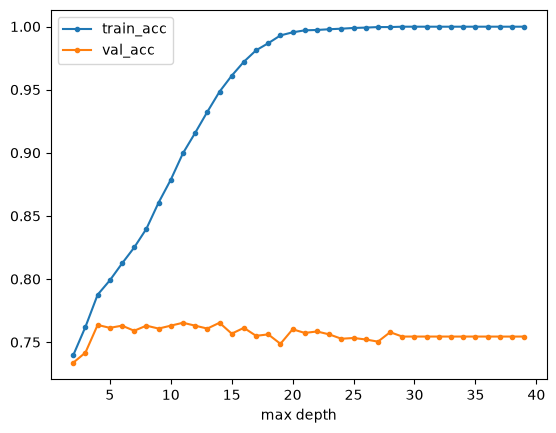

In [63]:
plt.plot(depth_list, train_acc_list, '.-', label='train_acc')
plt.plot(depth_list, val_acc_list, '.-', label='val_acc')
plt.xlabel('max depth')

plt.legend()

##### adjust leaf size

In [64]:
train_acc_list = []
val_acc_list = []

leaf_size_list = [2*i for i in range(1, 80)]
for leaf_size in leaf_size_list:

    tree = DecisionTreeClassifier(criterion="gini", max_depth=None, min_samples_leaf=leaf_size, random_state=42)

    tree.fit(x_train_df, y_train_df)

    train_pred = tree.predict(x_train_df)
    val_pred = tree.predict(x_val_df)

    train_acc = accuracy_score(y_train_df, train_pred)
    val_acc = accuracy_score(y_val_df, val_pred)
    
    train_acc_list.append(train_acc)
    val_acc_list.append(val_acc)

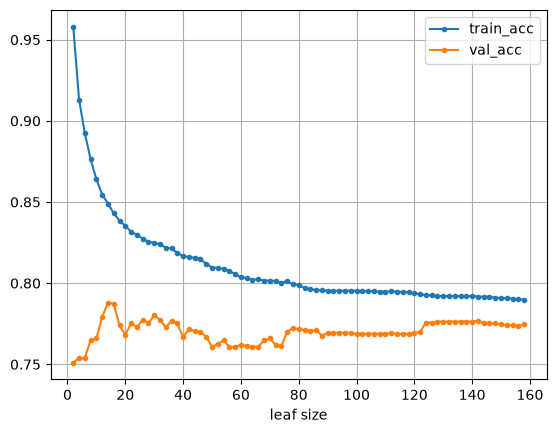

In [65]:
plt.plot(leaf_size_list, train_acc_list, '.-', label='train_acc')
plt.plot(leaf_size_list, val_acc_list, '.-', label='val_acc')
plt.xlabel('leaf size')
plt.grid()

plt.legend()

### Random Forest

In [78]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score

In [101]:
train_acc_list = []
val_acc_list = []
oob_acc_list = []

max_f_list = np.arange(2, x_train_df.shape[1], 2)


max_d = None
min_leaf = 1
# max_f = 'sqrt'


for max_f in max_f_list:

    rf = RandomForestClassifier(
        n_estimators=500,
        max_features=max_f,
        max_depth=max_d,
        min_samples_leaf=min_leaf,
        random_state=42,
        oob_score=True,
        n_jobs=-1
    )

    rf.fit(x_train_df, y_train_df)

    train_pred = rf.predict(x_train_df)
    val_pred = rf.predict(x_val_df)

    train_acc = accuracy_score(y_train_df, train_pred)
    val_acc = accuracy_score(y_val_df, val_pred)
    
    train_acc_list.append(train_acc)
    val_acc_list.append(val_acc)
    oob_acc_list.append(rf.oob_score_)

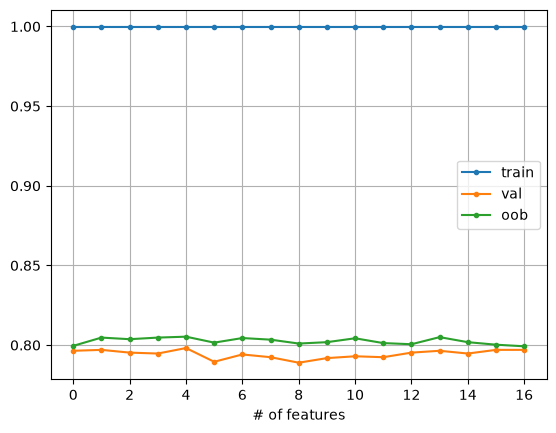

In [102]:
plt.plot(train_acc_list, '.-', label='train')
plt.plot(val_acc_list, '.-', label='val')
plt.plot(oob_acc_list, '.-', label='oob')
plt.xlabel('# of features')

plt.grid()
plt.legend()

---

In [116]:
def rf_test(n_tree, max_f, max_d, min_leaf, return_rf=False):
    rf = RandomForestClassifier(
        n_estimators=n_tree,
        max_features=max_f,
        max_depth=max_d,
        min_samples_leaf=min_leaf,
        random_state=42,
        oob_score=True,
        n_jobs=-1
    )

    rf.fit(x_train_df, y_train_df)

    train_pred = rf.predict(x_train_df)
    val_pred = rf.predict(x_val_df)

    train_acc = accuracy_score(y_train_df, train_pred)
    val_acc = accuracy_score(y_val_df, val_pred)
    
    if return_rf:
        return train_acc, val_acc, rf.oob_score_, rf
    else:
        return train_acc, val_acc, rf.oob_score_

In [134]:
train_acc_list = []
val_acc_list = []
oob_acc_list = []

n_tree = 500
max_d = None
min_leaf = 1
max_f = 4

for min_leaf in [2**i for i in range(8)]:
    a1, a2, a3 = rf_test(n_tree, max_f, max_d, min_leaf)
    train_acc_list.append(a1)
    val_acc_list.append(a2)
    oob_acc_list.append(a3)

0.8004600345025877


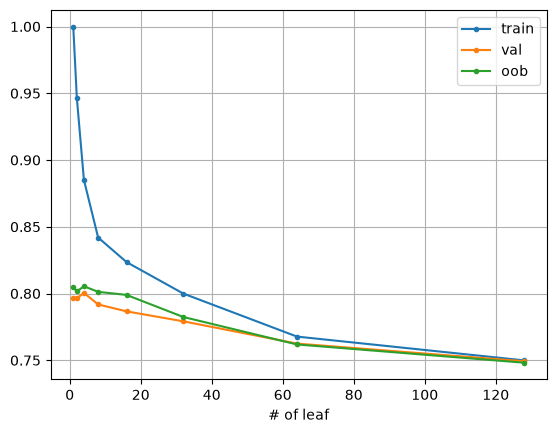

In [135]:
plt.plot([2**i for i in range(8)], train_acc_list, '.-', label='train')
plt.plot([2**i for i in range(8)], val_acc_list, '.-', label='val')
plt.plot([2**i for i in range(8)], oob_acc_list, '.-', label='oob')
plt.xlabel('# of leaf')

print(max(val_acc_list))
plt.grid()
plt.legend()

---

In [109]:
train_acc_list = []
val_acc_list = []
oob_acc_list = []

n_tree = 500
# max_d = None
min_leaf = 2
max_f = 4

max_d_list = np.arange(5, 50, 5)

for max_d in max_d_list:
    a1, a2, a3 = rf_test(n_tree, max_f, max_d, min_leaf)
    train_acc_list.append(a1)
    val_acc_list.append(a2)
    oob_acc_list.append(a3)

0.7993099482461185


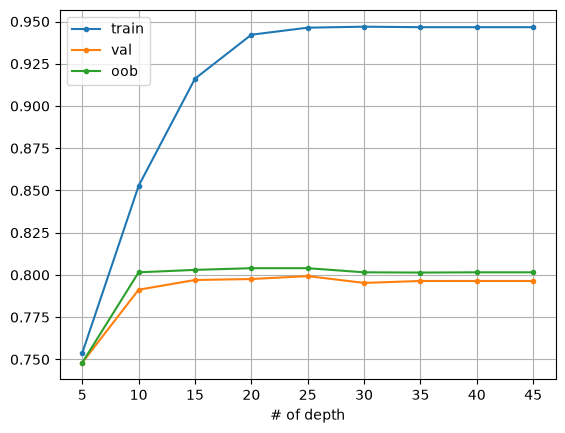

In [110]:
plt.plot(max_d_list, train_acc_list, '.-', label='train')
plt.plot(max_d_list, val_acc_list, '.-', label='val')
plt.plot(max_d_list, oob_acc_list, '.-', label='oob')
plt.xlabel('# of depth')

print(max(val_acc_list))
plt.grid()
plt.legend()

---

In [126]:
train_acc_list = []
val_acc_list = []
oob_acc_list = []

# n_tree = 500
max_d = None
min_leaf = 2
max_f = 4

n_tree_list = np.arange(100, 1000, 100)

for n_tree in n_tree_list:
    a1, a2, a3 = rf_test(n_tree, max_f, max_d, min_leaf)
    train_acc_list.append(a1)
    val_acc_list.append(a2)
    oob_acc_list.append(a3)

0.7998849913743531


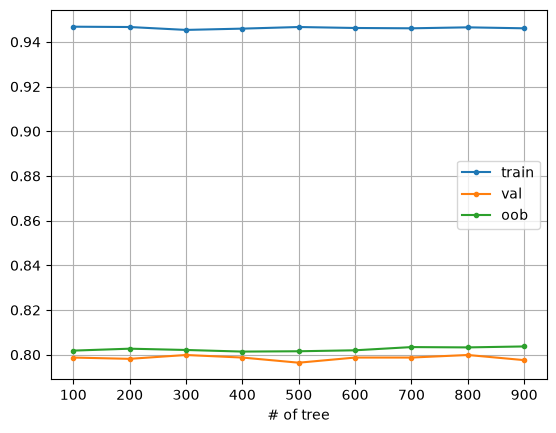

In [127]:
plt.plot(n_tree_list, train_acc_list, '.-', label='train')
plt.plot(n_tree_list, val_acc_list, '.-', label='val')
plt.plot(n_tree_list, oob_acc_list, '.-', label='oob')
plt.xlabel('# of tree')

print(max(val_acc_list))
plt.grid()
plt.legend()

In [136]:
n_tree = 300
max_f = 4
max_d = 25
min_leaf = 4

_, _, _, rf = rf_test(n_tree, max_f, max_d, min_leaf, return_rf=True)

##### submit

In [137]:
test = pd.read_csv(path + '/test.csv')
sample = pd.read_csv(path + '/sample_submission.csv')

test_df = getData(test, istest=True)
test_df = test_df.reindex(columns=dataset_x.columns, fill_value=0)

In [138]:
test_pred = rf.predict(test_df)

submit = sample.copy()
submit["Transported"] = test_pred.astype(bool)

In [139]:
submit

,PassengerId,Transported
0,0013_01,True
1,0018_01,False
2,0019_01,True
3,0021_01,True
4,0023_01,True
...,...,...
4272,9266_02,True
4273,9269_01,False
4274,9271_01,True
4275,9273_01,True


In [140]:
submit.to_csv(f'./data/submit_{datetime.now().isoformat()}.csv', index=False)
submit.to_csv(f'./submit.csv', index=False)

In [141]:
ls

data/                                   titanic_alpha_nueral_network.ipynb
submit.csv                              titanic_alpha_tree_model.ipynb
titanic_alpha_logic_registration.ipynb  titanic_dataset.ipynb
